### Q2. Generate a Correlated 2D Gaussian Dataset

We generate 500 samples from a two-dimensional Gaussian distribution with mean

$$
\mu =
\begin{bmatrix}
2 \\
-1
\end{bmatrix}
$$

and covariance matrix

$$
\Sigma =
\begin{bmatrix}
3 & 1.2 \\
1.2 & 1
\end{bmatrix}.
$$

The positive off-diagonal covariance value indicates that the two features are positively correlated.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def generate_data(n_samples=500, seed=0):
    mean = np.array([2.0, -1.0])

    covariance = np.array([
        [3.0, 1.2],
        [1.2, 1.0]
    ])

    rng = np.random.default_rng(seed)

    X = rng.multivariate_normal(
        mean,
        covariance,
        size=n_samples
    )

    return X

X = generate_data()

print("Shape:", X.shape)
print("Sample mean:", np.mean(X, axis=0))
print("Sample covariance:")
print(np.cov(X, rowvar=False))

Matplotlib is building the font cache; this may take a moment.


Shape: (500, 2)
Sample mean: [ 2.1523992  -0.93464455]
Sample covariance:
[[2.91615571 1.1656626 ]
 [1.1656626  0.95302538]]


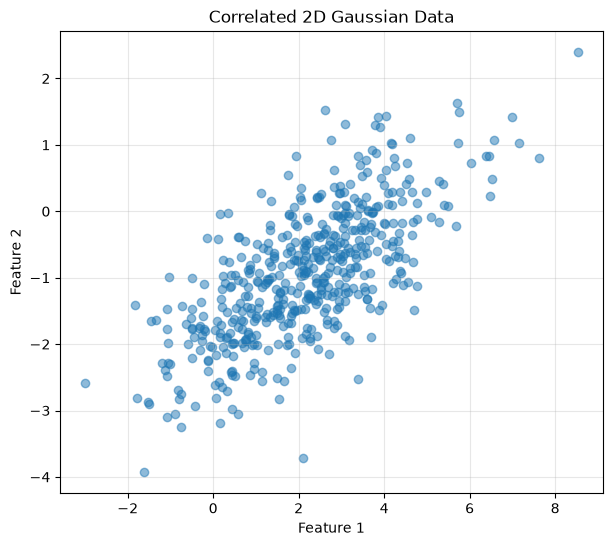

In [3]:
plt.figure(figsize=(7, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    alpha=0.5
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Correlated 2D Gaussian Data")

plt.grid(alpha=0.3)
plt.show()

The scatter plot shows an elongated distribution with an upward trend, indicating a positive correlation between the two features.

The covariance matrix has a positive off-diagonal entry of 1.2. The corresponding correlation coefficient is

$$
\rho =
\frac{\mathrm{Cov}(X_1,X_2)}
{\sqrt{\mathrm{Var}(X_1)\mathrm{Var}(X_2)}}
=
\frac{1.2}{\sqrt{3 \cdot 1}}
\approx 0.69.
$$

Therefore, the two variables have a moderately strong positive correlation. Larger values of the first feature tend to be associated with larger values of the second feature.

### Q3. PCA from Scratch

PCA finds directions along which the centered data has the largest variance.

The main steps are:

1. Center the data by subtracting the mean.
2. Compute the covariance matrix.
3. Compute the eigenvalues and eigenvectors of the covariance matrix.
4. Sort the eigenvectors according to eigenvalues in descending order.
5. Use the eigenvectors as principal component directions.

In [ ]:
def pca(X):
    # Center the data
    mean = np.mean(X, axis=0)
    centered = X - mean
    # Compute covariance matrix
    covariance = centered.T @ centered / (X.shape[0] - 1)
    # Eigendecomposition
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    # Sort by eigenvalue in descending order
    idx = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[idx]
    components = eigenvectors[:, idx]

    scores = centered @ components

    return {
        "mean": mean,
        "centered": centered,
        "covariance": covariance,
        "eigenvalues": eigenvalues,
        "components": components,
        "scores": scores
    }

result = pca(X)

print("Mean:")
print(result["mean"])

print("\nCovariance matrix:")
print(result["covariance"])

print("\nEigenvalues:")
print(result["eigenvalues"])

print("\nPrincipal components:")
print(result["components"])

Mean:
[ 2.1523992  -0.93464455]

Covariance matrix:
[[2.91615571 1.1656626 ]
 [1.1656626  0.95302538]]

Eigenvalues:
[3.45848013 0.41070096]

Principal components:
[[-0.90667478  0.42183036]
 [-0.42183036 -0.90667478]]


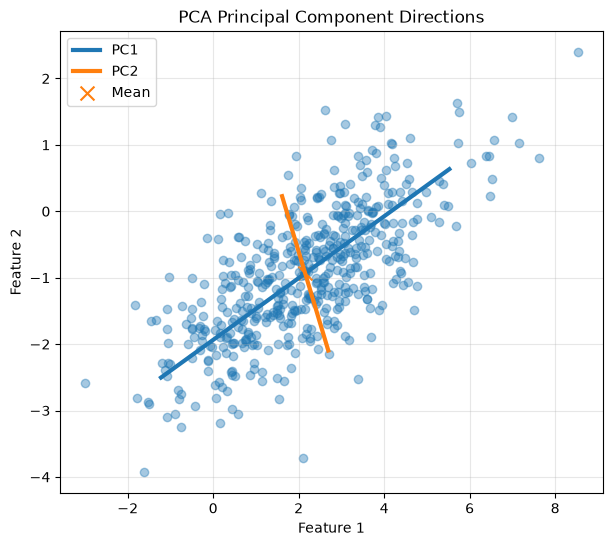

In [ ]:
mean = result["mean"]
components = result["components"]
eigenvalues = result["eigenvalues"]

plt.figure(figsize=(7, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    alpha=0.4
)

for i in range(2):
    direction = components[:, i]
    scale = 2 * np.sqrt(eigenvalues[i])

    plt.plot(
        [mean[0] - scale * direction[0],
         mean[0] + scale * direction[0]],
        [mean[1] - scale * direction[1],
         mean[1] + scale * direction[1]],
        linewidth=3,
        label=f"PC{i+1}"
    )

plt.scatter(
    mean[0],
    mean[1],
    marker="x",
    s=100,
    label="Mean"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("PCA Principal Component Directions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The first principal component (PC1) follows the direction in which the data has the largest variance. Because the two features are positively correlated, PC1 approximately follows the elongated direction of the point cloud.

The second principal component (PC2) is orthogonal to PC1 and represents the remaining direction of variation.

This agrees with the PCA objective from Q1: PCA chooses the direction $u$ that maximizes

$$
u^T \Sigma u.
$$

Therefore, the eigenvector associated with the largest eigenvalue becomes the first principal component.

### Q4. Explained Variance

The proportion of total variance explained by the $i$-th principal component is

$$
\text{Explained Variance Ratio}_i
=
\frac{\lambda_i}{\sum_j \lambda_j},
$$

where $\lambda_i$ is the eigenvalue corresponding to the $i$-th principal component.

A larger eigenvalue means that the corresponding principal component captures more variation in the data.

In [6]:
def explained_variance(eigenvalues):
    return eigenvalues / np.sum(eigenvalues)

variance_ratio = explained_variance(result["eigenvalues"])

print("Explained variance ratio:")
print(variance_ratio)

print("\nPC1 explained variance: {:.2f}%".format(variance_ratio[0] * 100))
print("PC2 explained variance: {:.2f}%".format(variance_ratio[1] * 100))

Explained variance ratio:
[0.89385326 0.10614674]

PC1 explained variance: 89.39%
PC2 explained variance: 10.61%


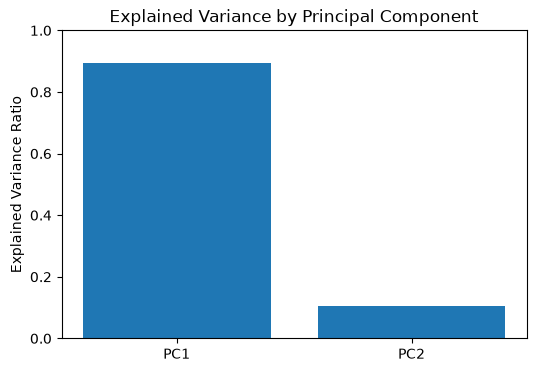

In [7]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["PC1", "PC2"],
    variance_ratio
)

plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by Principal Component")
plt.ylim(0, 1)

plt.show()

PC1 explains most of the total variance in the dataset, while PC2 explains only a relatively small fraction. This is expected because the two original features are positively correlated, so much of their variation occurs along a common direction.

Because PC1 retains most of the variance, the original two-dimensional dataset could be reduced to one dimension by keeping only PC1 while preserving most of the information in terms of variance.

However, dimensionality reduction introduces a trade-off. Keeping fewer principal components reduces the dimensionality and makes the representation more compact, but some variance is lost. In this case, reducing the data from two dimensions to one dimension would preserve approximately 89% of the total variance while discarding approximately 11%.

Therefore, PCA allows us to choose a lower-dimensional representation depending on how much information loss is acceptable.